# Report 1: 
### Which social media platform has the most negative effect on sleep between different academic levels, and which academic level has the worst effect out of them all?

##### Imports and setup

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 120)

df = pd.read_csv("Social_media_impact_on_life.csv")
print(df.shape)
df.head()

(4500, 16)


,Student_ID,Age,Gender,Academic_Level,Primary_Platform,Daily_Usage_Hours,Weekend_Extra_Hours,Device_Type,Sleep_Duration_Hours,Sleep_Quality_Score,Late_Night_Usage,Social_Comparison_Frequency,Perceived_Stress_Score,Mental_Health_Index,Academic_Performance_GPA,Overall_Impact
0,STU_2024000,19,Female,Undergraduate,Snapchat,7.5,1.5,Smartphone,5.9,2,True,Always,20.0,73,2.73,Neutral
1,STU_2024001,19,Female,Undergraduate,Instagram,4.6,1.3,Smartphone,7.9,3,True,Sometimes,17.0,90,3.21,Beneficial
2,STU_2024002,17,Female,High School,TikTok,10.9,1.7,Smartphone,5.2,1,True,Frequently,18.0,70,3.00,Neutral
3,STU_2024003,16,Female,High School,YouTube,6.0,2.3,Tablet,7.6,4,True,Sometimes,15.0,82,3.42,Beneficial
4,STU_2024004,17,Male,High School,LinkedIn,3.3,2.6,Smartphone,7.6,4,True,Never,16.0,84,3.41,Beneficial


## EDA on the Dataset

In [ ]:
cols = ["Academic_Level", "Primary_Platform", "Daily_Usage_Hours",
        "Sleep_Duration_Hours", "Sleep_Quality_Score", "Late_Night_Usage"]
data = df[cols].copy()

print("Missing values in the columns used:")
print(data.isna().sum())
print("\nDuplicate student IDs:", df["Student_ID"].duplicated().sum())
print("\nDtypes:")
print(data.dtypes)

Missing values in the columns used:
Academic_Level          0
Primary_Platform        0
Daily_Usage_Hours       0
Sleep_Duration_Hours    0
Sleep_Quality_Score     0
Late_Night_Usage        0
dtype: int64

Duplicate student IDs: 0

Dtypes:
Academic_Level           object
Primary_Platform         object
Daily_Usage_Hours       float64
Sleep_Duration_Hours    float64
Sleep_Quality_Score       int64
Late_Night_Usage           bool
dtype: object


In [ ]:
data["Late_Night_Usage"] = data["Late_Night_Usage"].astype(bool)
level_order = ["High School", "Undergraduate", "Postgraduate"]
data["Academic_Level"] = pd.Categorical(data["Academic_Level"], level_order, ordered=True)

print(data["Academic_Level"].value_counts().reindex(level_order))
print()
print(data["Primary_Platform"].value_counts())
data[["Daily_Usage_Hours", "Sleep_Duration_Hours", "Sleep_Quality_Score"]].describe().round(2)

Academic_Level
High School      1477
Undergraduate    2777
Postgraduate      246
Name: count, dtype: int64

Primary_Platform
Instagram      1453
TikTok         1226
YouTube         818
Snapchat        472
Reddit          229
X (Twitter)     206
LinkedIn         96
Name: count, dtype: int64


,Daily_Usage_Hours,Sleep_Duration_Hours,Sleep_Quality_Score
count,4500.0,4500.00,4500.00
mean,5.3,6.70,2.47
std,2.6,1.19,1.03
min,0.9,3.00,1.00
25%,3.4,6.00,2.00
50%,4.7,6.80,3.00
75%,6.6,7.50,3.00
max,14.0,10.50,5.00


## Statistical Analysis
Sleep harm is measured three ways (lower sleep duration and quality = worse, higher late-night share = worse). To combine them, each metric is turned into a z-score across all students, direction-aligned so that **higher = worse**, and averaged into a **Sleep Harm Index**. An index of 0 is the dataset average. Positive values are worse than average.

In [ ]:
z = lambda s: (s - s.mean()) / s.std()
data["Sleep_Harm_Index"] = (
    -z(data["Sleep_Duration_Hours"])
    - z(data["Sleep_Quality_Score"])
    + z(data["Late_Night_Usage"].astype(float))
) / 3
data["Heavy_User"] = data["Daily_Usage_Hours"] >= 7
data["Late"] = data["Late_Night_Usage"].astype(float)

#### Sleep Duration (Hours) vs. Sleep Quality Score

                      Daily_Usage_Hours  Sleep_Duration_Hours  Sleep_Quality_Score
Daily_Usage_Hours                  1.00                 -0.72                -0.68
Sleep_Duration_Hours              -0.72                  1.00                 0.75
Sleep_Quality_Score               -0.68                  0.75                 1.00


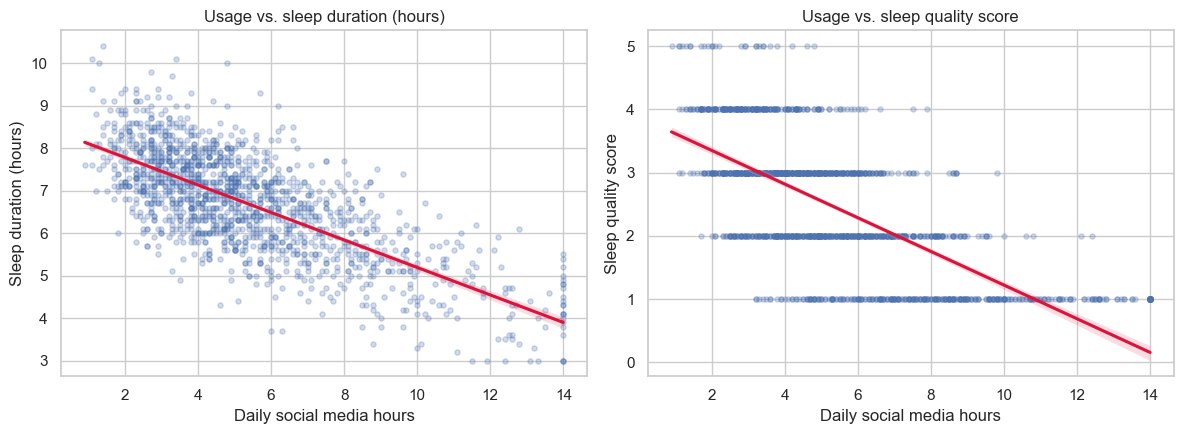

In [ ]:
corr = data[["Daily_Usage_Hours", "Sleep_Duration_Hours", "Sleep_Quality_Score"]].corr().round(2)
print(corr)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, y, t in zip(axes, ["Sleep_Duration_Hours", "Sleep_Quality_Score"],
                    ["Sleep duration (hours)", "Sleep quality score"]):
    sns.regplot(data=data.sample(1500, random_state=1), x="Daily_Usage_Hours", y=y,
                scatter_kws={"alpha": .25, "s": 14}, line_kws={"color": "crimson"}, ax=ax)
    ax.set_xlabel("Daily social media hours"); ax.set_ylabel(t)
    ax.set_title(f"Usage vs. {t.lower()}")
plt.tight_layout(); plt.show()

### Platform Comparison within Each Academic Level

In [ ]:
grp = (data.groupby(["Academic_Level", "Primary_Platform"], observed=True)
       .agg(n=("Sleep_Duration_Hours", "size"),
            sleep_hours=("Sleep_Duration_Hours", "mean"),
            sleep_quality=("Sleep_Quality_Score", "mean"),
            late_night_share=("Late", "mean"),
            daily_hours=("Daily_Usage_Hours", "mean"),
            harm_index=("Sleep_Harm_Index", "mean"))
       .round(3).reset_index())
grp

,Academic_Level,Primary_Platform,n,sleep_hours,sleep_quality,late_night_share,daily_hours,harm_index
0,High School,Instagram,471,6.604,2.406,0.584,5.338,0.046
1,High School,LinkedIn,23,6.678,2.391,0.783,5.648,0.165
2,High School,Reddit,78,6.683,2.397,0.564,5.005,0.013
3,High School,Snapchat,146,6.760,2.500,0.596,5.426,-0.020
4,High School,TikTok,419,6.717,2.453,0.601,5.376,0.011
5,High School,X (Twitter),59,6.903,2.644,0.576,4.929,-0.120
6,High School,YouTube,281,6.654,2.427,0.601,5.330,0.037
7,Undergraduate,Instagram,899,6.774,2.506,0.584,5.203,-0.034
8,Undergraduate,LinkedIn,64,6.844,2.516,0.547,5.178,-0.082
9,Undergraduate,Reddit,139,6.585,2.410,0.597,5.528,0.059


### Bar charts of mean sleep by platform within each level

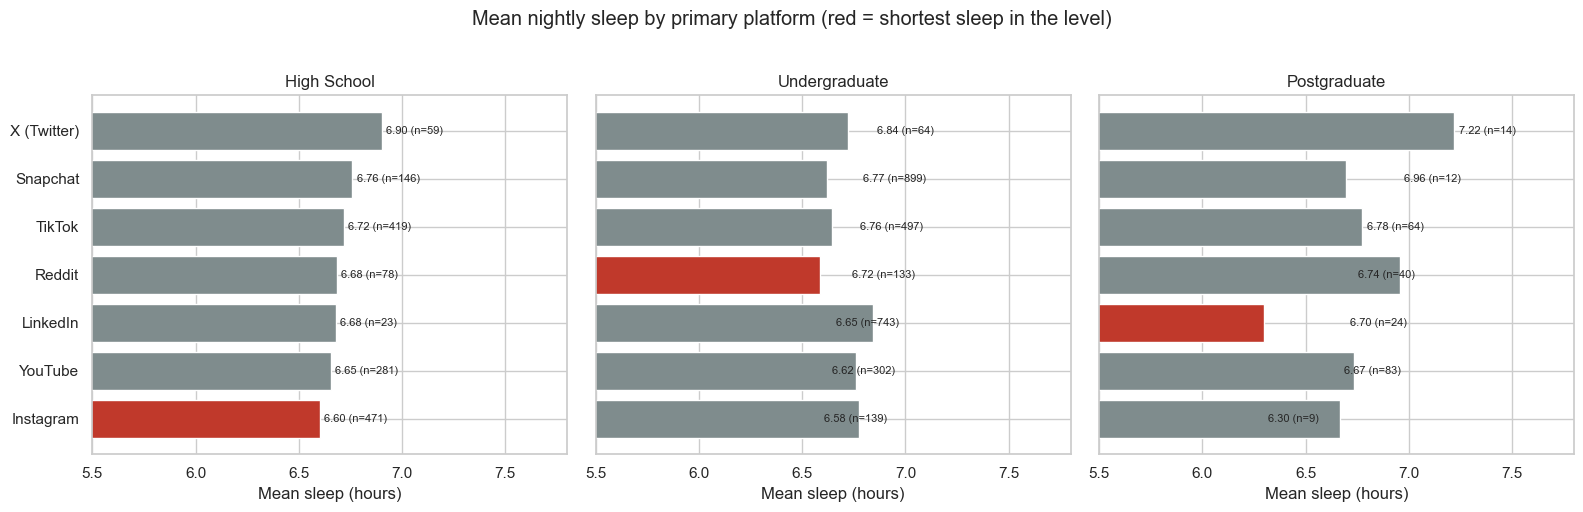

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
for ax, lvl in zip(axes, level_order):
    sub = grp[grp.Academic_Level == lvl].sort_values("sleep_hours")
    colors = ["#c0392b" if i == 0 else "#7f8c8d" for i in range(len(sub))]
    ax.barh(sub.Primary_Platform, sub.sleep_hours, color=colors)
    for y, (v, n) in enumerate(zip(sub.sleep_hours, sub.n)):
        ax.text(v + .02, y, f"{v:.2f} (n={n})", va="center", fontsize=8)
    ax.set_xlim(5.5, 7.8); ax.set_title(lvl); ax.set_xlabel("Mean sleep (hours)")
fig.suptitle("Mean nightly sleep by primary platform (red = shortest sleep in the level)", y=1.02)
plt.tight_layout(); plt.show()

### Worst Platform Per Level

In [ ]:
MIN_N = 30
grp["reliable"] = grp["n"] >= MIN_N

def top_platform(frame, label):
    idx = frame.groupby("Academic_Level", observed=True)["harm_index"].idxmax()
    out = frame.loc[idx, ["Academic_Level", "Primary_Platform", "n", "sleep_hours",
                          "sleep_quality", "late_night_share", "harm_index"]].copy()
    out["Academic_Level"] = pd.Categorical(out["Academic_Level"], level_order, ordered=True)
    out = out.sort_values("Academic_Level").reset_index(drop=True)
    print(label)
    return out

display(top_platform(grp, "Worst platform per level, all groups:"))
worst30 = top_platform(grp[grp.reliable], f"Worst platform per level, groups with n >= {MIN_N} (used for conclusions):")
display(worst30)

Worst platform per level, all groups:


,Academic_Level,Primary_Platform,n,sleep_hours,sleep_quality,late_night_share,harm_index
0,High School,LinkedIn,23,6.678,2.391,0.783,0.165
1,Undergraduate,Reddit,139,6.585,2.410,0.597,0.059
2,Postgraduate,YouTube,40,6.735,2.350,0.600,0.038


Worst platform per level, groups with n >= 30 (used for conclusions):


,Academic_Level,Primary_Platform,n,sleep_hours,sleep_quality,late_night_share,harm_index
0,High School,Instagram,471,6.604,2.406,0.584,0.046
1,Undergraduate,Reddit,139,6.585,2.410,0.597,0.059
2,Postgraduate,YouTube,40,6.735,2.350,0.600,0.038


### Ranked Sleep Harm Index chart by platform within each level

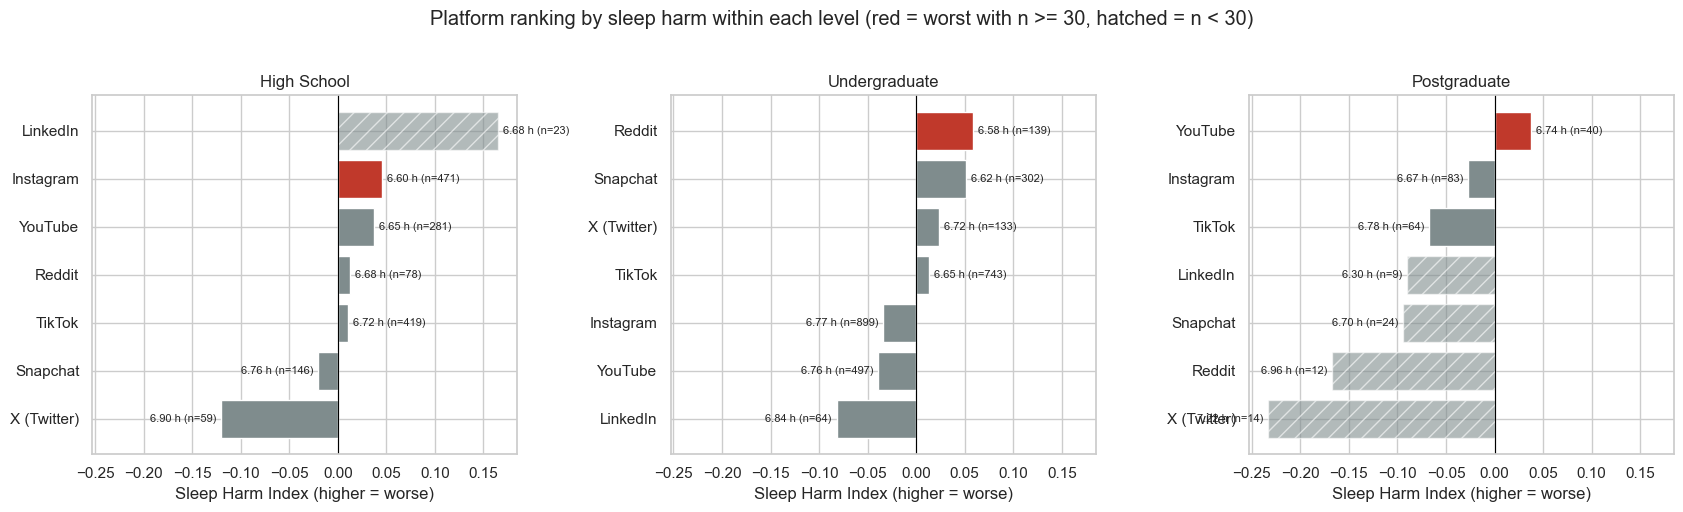

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharex=True)
for ax, l in zip(axes, level_order):
    sub = grp[grp.Academic_Level == l].sort_values("harm_index")
    worst_name = sub[sub.reliable].sort_values("harm_index").iloc[-1].Primary_Platform
    for y, r in enumerate(sub.itertuples()):
        ax.barh(y, r.harm_index, color="#c0392b" if r.Primary_Platform == worst_name else "#7f8c8d",
                hatch="//" if not r.reliable else None, edgecolor="white", alpha=.6 if not r.reliable else 1)
        ax.text(r.harm_index + (0.005 if r.harm_index >= 0 else -0.005), y,
                f"{r.sleep_hours:.2f} h (n={r.n})", va="center",
                ha="left" if r.harm_index >= 0 else "right", fontsize=8)
    ax.set_yticks(range(len(sub))); ax.set_yticklabels(sub.Primary_Platform)
    ax.axvline(0, color="black", lw=.8); ax.set_title(l); ax.set_xlabel("Sleep Harm Index (higher = worse)")
fig.suptitle("Platform ranking by sleep harm within each level (red = worst with n >= 30, hatched = n < 30)", y=1.02)
plt.tight_layout(); plt.show()

### Aggregate stats per academic level

In [ ]:
lvl = (data.groupby("Academic_Level", observed=True)
       .agg(n=("Sleep_Duration_Hours", "size"),
            sleep_hours=("Sleep_Duration_Hours", "mean"),
            sleep_quality=("Sleep_Quality_Score", "mean"),
            late_night_share=("Late", "mean"),
            mean_daily_hours=("Daily_Usage_Hours", "mean"),
            harm_index=("Sleep_Harm_Index", "mean"))
       .round(3))
lvl["harm_rank"] = lvl["harm_index"].rank(ascending=False).astype(int)
lvl.sort_values("harm_index", ascending=False)

,n,sleep_hours,sleep_quality,late_night_share,mean_daily_hours,harm_index,harm_rank
Academic_Level,,,,,,,
High School,1477,6.678,2.441,0.595,5.327,0.021,1
Undergraduate,2777,6.710,2.483,0.587,5.293,-0.007,2
Postgraduate,246,6.741,2.533,0.553,5.140,-0.054,3


### Bar charts comparing academic levels on each sleep measure

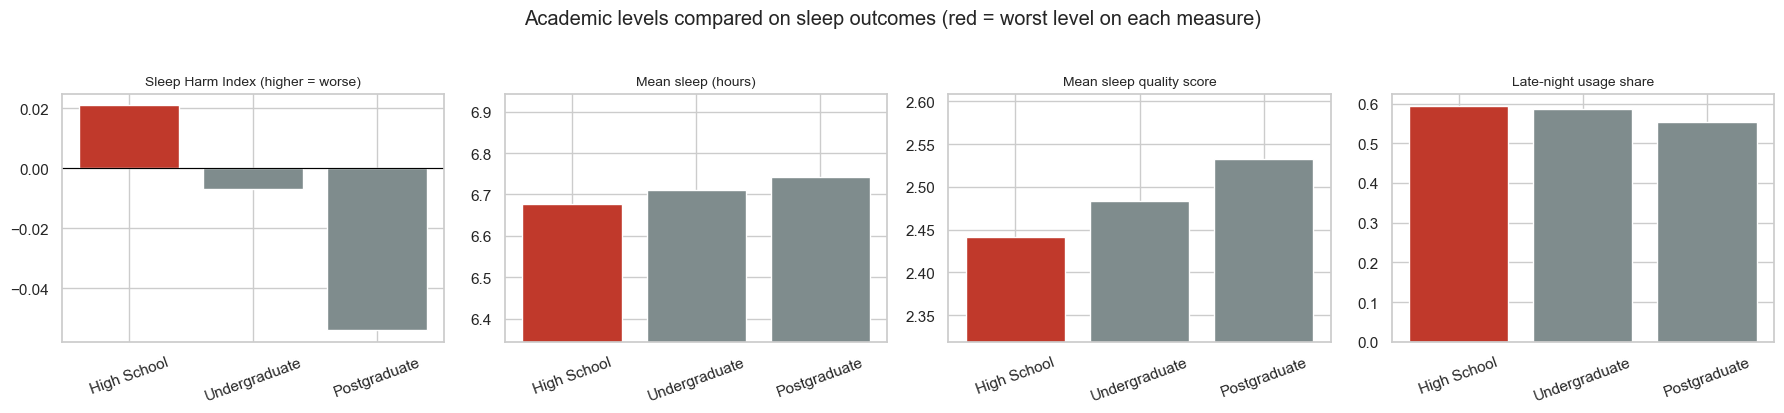

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
colors = ["#c0392b" if l == lvl.harm_index.idxmax() else "#7f8c8d" for l in lvl.index]
for ax, (c, t, worst_is_low) in zip(axes, [("harm_index", "Sleep Harm Index (higher = worse)", False),
                                           ("sleep_hours", "Mean sleep (hours)", True),
                                           ("sleep_quality", "Mean sleep quality score", True),
                                           ("late_night_share", "Late-night usage share", False)]):
    cols = colors
    if worst_is_low:
        cols = ["#c0392b" if l == lvl[c].idxmin() else "#7f8c8d" for l in lvl.index]
    ax.bar(lvl.index.astype(str), lvl[c], color=cols)
    ax.set_title(t, fontsize=10); ax.tick_params(axis="x", rotation=20)
    if c == "harm_index": ax.axhline(0, color="black", lw=.8)
    if c in ("sleep_hours", "sleep_quality"):
        ax.set_ylim(lvl[c].min() * .95, lvl[c].max() * 1.03)
fig.suptitle("Academic levels compared on sleep outcomes (red = worst level on each measure)", y=1.03)
plt.tight_layout(); plt.show()